# ORBITALROUTE AI
## Investigación de Machine Learning y complejidad computacional para rutas de menor costo

**Asignatura:** Complejidad Computacional  
**Proyecto:** OrbitalRoute AI  
**Tema central:** predicción de calidad de servicio (QoS) mediante Machine Learning y evaluación de algoritmos de optimización de rutas.

### Planteamiento del problema
En una red satelital, la ruta de menor distancia no necesariamente representa la mejor ruta de comunicación. La latencia, la pérdida de paquetes, la disponibilidad y la velocidad relativa de los enlaces también influyen en el costo operativo. Por ello, este estudio utiliza modelos de Machine Learning para estimar la latencia de enlaces y emplea esas estimaciones como parte del peso de las aristas de un grafo. Después se comparan algoritmos de búsqueda de caminos y su complejidad computacional.

### Objetivo general
Evaluar cómo la predicción de métricas QoS mediante modelos de Machine Learning puede apoyar la selección de rutas de menor costo, y analizar la eficiencia computacional de los algoritmos utilizados para encontrar dichos caminos.

### Objetivos específicos
1. Limpiar y explorar las bases de datos de OrbitalRoute AI.
2. Entrenar y comparar modelos de regresión para predecir latencia.
3. Evaluar los modelos con MAE, RMSE y \(R^2\), respetando el orden temporal.
4. Integrar la latencia predicha en el costo de enlaces de una red satelital representada mediante un grafo.
5. Comparar rutas obtenidas por Dijkstra y Bellman-Ford.
6. Analizar la complejidad temporal y espacial de la construcción del grafo y de los algoritmos de caminos.

> **Alcance y honestidad de los datos:** los dos CSV incluidos son conjuntos sintéticos/didácticos previamente preparados para OrbitalRoute AI. No representan mediciones operativas de satélites ni telemetría real. Los resultados sirven para demostrar y evaluar el procedimiento; no deben presentarse como validación de una red satelital desplegada.

## 1. Instalación e importación de bibliotecas

Si falta alguna biblioteca, ejecuta en una celda:
`%pip install pandas numpy matplotlib scikit-learn networkx`

Se utilizan pandas y NumPy para datos, Matplotlib para gráficas, scikit-learn para Machine Learning y NetworkX para grafos y rutas.

In [3]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("Bibliotecas cargadas correctamente.")

Bibliotecas cargadas correctamente.


## 2. Carga de las bases de datos

- `OrbitalRoute_AI_base_sintetica.csv`: 240 observaciones temporales de latencia, pérdida de paquetes, disponibilidad, distancia y velocidad relativa.
- `orbitalroute_base_sintetica.csv`: 120 observaciones didácticas de 12 satélites, con posición, velocidad y métricas sintéticas de enlace.

Ambas bases se conservan separadas porque representan estructuras diferentes: una contiene observaciones QoS temporales y la otra contiene estados de satélites para construir una topología.

In [4]:
BASE_DIR = Path(".")
qos_path = BASE_DIR / "OrbitalRoute_AI_base_sintetica.csv"
orbit_path = BASE_DIR / "orbitalroute_base_sintetica.csv"

if not qos_path.exists() or not orbit_path.exists():
    raise FileNotFoundError(
        "Coloca los dos archivos CSV en la misma carpeta que este notebook."
    )

qos_raw = pd.read_csv(qos_path)
orbit_raw = pd.read_csv(orbit_path)

print("Base QoS:", qos_raw.shape)
print("Base orbital:", orbit_raw.shape)
display(qos_raw.head())
display(orbit_raw.head())

Base QoS: (240, 6)
Base orbital: (120, 12)


,timestamp,latency_ms,packet_loss_pct,availability_pct,distance_km,relative_velocity_km_s
0,2026-01-01 00:00:00,54.942641,1.226349,98.050928,3982.802219,6.237772
1,2026-01-01 00:05:00,38.344314,0.652886,97.731890,2474.952979,5.996446
2,2026-01-01 00:10:00,55.902109,1.764919,96.143371,4363.690640,1.821541
3,2026-01-01 00:15:00,47.949178,0.951123,99.839098,3638.156131,4.027695
4,2026-01-01 00:20:00,24.918836,0.108180,96.412011,923.798065,4.584517


,satellite_id,time_min,x_km,y_km,z_km,vx_km_s,vy_km_s,vz_km_s,latency_ms_synthetic,packet_loss_pct_synthetic,capacity_mbps_synthetic,data_type
0,SAT-01,0.0,6.921000e+03,0.00000,23.840320,-0.000000,7.500000e+00,0.058804,12.457076,0.540004,715.352419,SINTETICO_DIDACTICO
1,SAT-02,0.0,5.993762e+03,3460.50000,53.467168,-3.750000,6.495191e+00,0.053715,14.610847,0.312241,657.069633,SINTETICO_DIDACTICO
2,SAT-03,0.0,3.460500e+03,5993.76182,79.450317,-6.495191,3.750000e+00,0.044966,14.591761,0.720939,682.929892,SINTETICO_DIDACTICO
3,SAT-04,0.0,4.237890e-13,6921.00000,100.019059,-7.500000,4.592425e-16,0.033152,14.320434,1.019849,700.992366,SINTETICO_DIDACTICO
4,SAT-05,0.0,-3.460500e+03,5993.76182,113.771666,-6.495191,-3.750000e+00,0.019079,12.099046,1.081810,712.557818,SINTETICO_DIDACTICO


## 3. Limpieza y validación de datos

Se convierten los tipos, se eliminan duplicados y se comprueban rangos físicamente razonables para las variables de la base didáctica. Los registros se ordenan cronológicamente antes de entrenar los modelos.

In [5]:
qos = qos_raw.copy()
orbit = orbit_raw.copy()

qos["timestamp"] = pd.to_datetime(qos["timestamp"], errors="coerce")
qos_numeric = [
    "latency_ms", "packet_loss_pct", "availability_pct",
    "distance_km", "relative_velocity_km_s"
]
for col in qos_numeric:
    qos[col] = pd.to_numeric(qos[col], errors="coerce")

qos = qos.dropna(subset=["timestamp"] + qos_numeric)
qos = qos.drop_duplicates().sort_values("timestamp").reset_index(drop=True)

orbit_numeric = [
    "time_min", "x_km", "y_km", "z_km", "vx_km_s", "vy_km_s",
    "vz_km_s", "latency_ms_synthetic",
    "packet_loss_pct_synthetic", "capacity_mbps_synthetic"
]
for col in orbit_numeric:
    orbit[col] = pd.to_numeric(orbit[col], errors="coerce")

orbit = orbit.dropna(subset=["satellite_id"] + orbit_numeric)
orbit = orbit.drop_duplicates().sort_values(["time_min", "satellite_id"]).reset_index(drop=True)

# Validación de rangos de la base QoS.
qos = qos[
    (qos["latency_ms"] >= 0) &
    (qos["packet_loss_pct"].between(0, 100)) &
    (qos["availability_pct"].between(0, 100)) &
    (qos["distance_km"] >= 0) &
    (qos["relative_velocity_km_s"] >= 0)
].reset_index(drop=True)

print("Registros QoS después de limpieza:", len(qos))
print("Registros orbitales después de limpieza:", len(orbit))
print("Satélites:", orbit["satellite_id"].nunique())
print("Instantes:", orbit["time_min"].nunique())
print("Valores faltantes QoS:")
display(qos.isna().sum().to_frame("faltantes"))

Registros QoS después de limpieza: 240
Registros orbitales después de limpieza: 120
Satélites: 12
Instantes: 10
Valores faltantes QoS:


,faltantes
timestamp,0
latency_ms,0
packet_loss_pct,0
availability_pct,0
distance_km,0
relative_velocity_km_s,0


## 4. Análisis exploratorio de datos (EDA)

Primero se describe la distribución de las métricas. Las gráficas permiten identificar la relación entre distancia y latencia, la variación temporal de QoS y las correlaciones presentes en el conjunto sintético.

In [6]:
display(qos[qos_numeric].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
latency_ms,240.0,41.397,12.166,15.899,31.478,41.682,50.666,66.661
packet_loss_pct,240.0,1.561,0.856,0.014,0.895,1.582,2.308,2.996
availability_pct,240.0,97.904,1.192,96.005,96.843,97.857,98.957,99.972
distance_km,240.0,2718.877,1292.467,533.130,1535.335,2694.295,3862.599,4965.690
relative_velocity_km_s,240.0,3.803,2.175,0.140,1.844,3.936,5.835,7.493


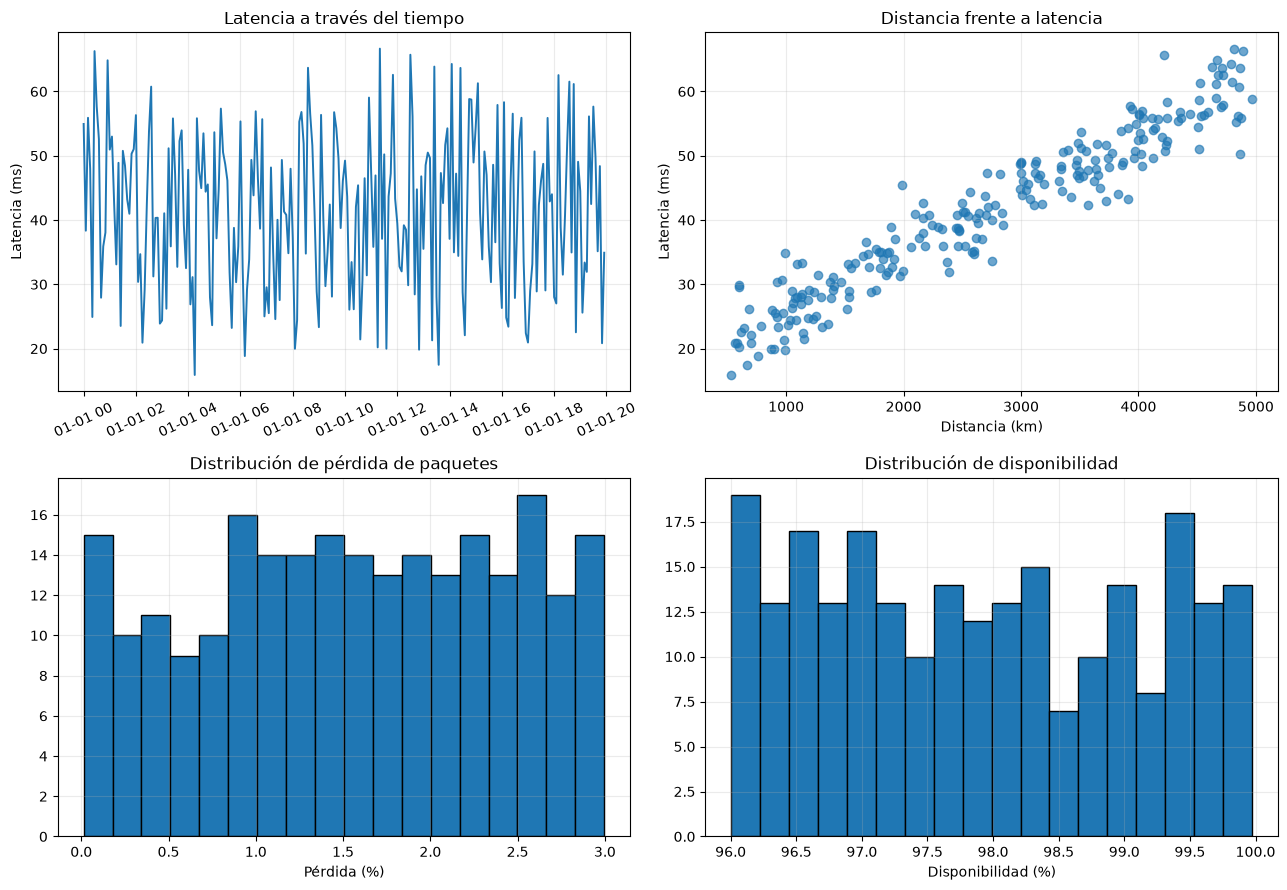

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(qos["timestamp"], qos["latency_ms"], linewidth=1.4)
axes[0, 0].set_title("Latencia a través del tiempo")
axes[0, 0].set_ylabel("Latencia (ms)")
axes[0, 0].tick_params(axis="x", rotation=25)

axes[0, 1].scatter(qos["distance_km"], qos["latency_ms"], alpha=0.65)
axes[0, 1].set_title("Distancia frente a latencia")
axes[0, 1].set_xlabel("Distancia (km)")
axes[0, 1].set_ylabel("Latencia (ms)")

axes[1, 0].hist(qos["packet_loss_pct"], bins=18, edgecolor="black")
axes[1, 0].set_title("Distribución de pérdida de paquetes")
axes[1, 0].set_xlabel("Pérdida (%)")

axes[1, 1].hist(qos["availability_pct"], bins=18, edgecolor="black")
axes[1, 1].set_title("Distribución de disponibilidad")
axes[1, 1].set_xlabel("Disponibilidad (%)")

plt.tight_layout()
plt.show()

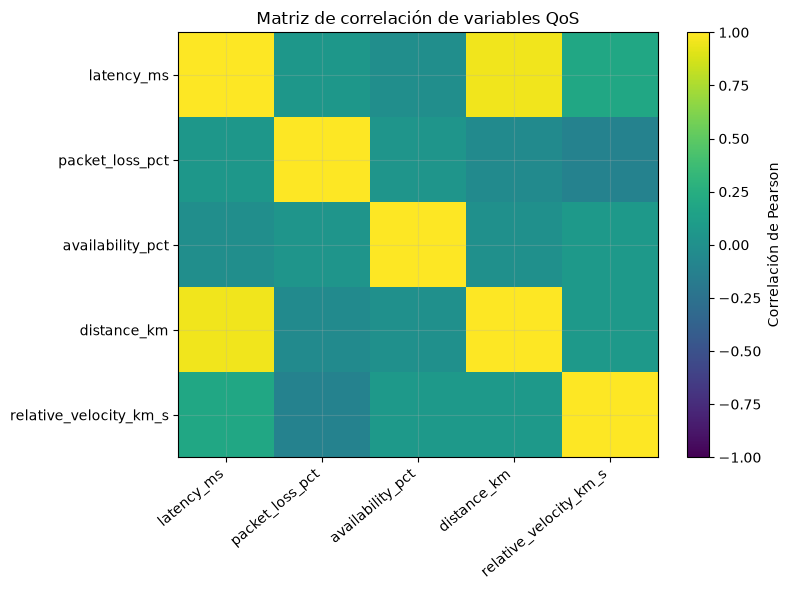

,latency_ms,packet_loss_pct,availability_pct,distance_km,relative_velocity_km_s
latency_ms,1.000,0.055,-0.015,0.958,0.194
packet_loss_pct,0.055,1.000,0.044,-0.039,-0.112
availability_pct,-0.015,0.044,1.000,0.002,0.083
distance_km,0.958,-0.039,0.002,1.000,0.080
relative_velocity_km_s,0.194,-0.112,0.083,0.080,1.000


In [8]:
corr = qos[qos_numeric].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Matriz de correlación de variables QoS")
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
plt.tight_layout()
plt.show()
display(corr.round(3))

## 5. Variable objetivo y formulación del costo QoS

El modelo principal de Machine Learning predice `latency_ms`. La latencia estimada se incorpora después al costo de cada enlace.

Para el análisis de rutas se utiliza la función didáctica:

\[
C_{QoS} = L + 1.8P + 0.8(100-A)
\]

donde:
- \(L\): latencia en milisegundos (predicha por ML).
- \(P\): pérdida de paquetes en porcentaje.
- \(A\): disponibilidad en porcentaje.

Esta función es una **función de costo ponderada de carácter experimental**, no una tarifa monetaria ni una fórmula universal. Sus coeficientes deben calibrarse con requisitos reales del sistema.

In [9]:
qos["qos_cost_observed"] = (
    qos["latency_ms"]
    + 1.8 * qos["packet_loss_pct"]
    + 0.8 * (100 - qos["availability_pct"])
)
display(qos[["latency_ms", "packet_loss_pct", "availability_pct", "qos_cost_observed"]].head())

,latency_ms,packet_loss_pct,availability_pct,qos_cost_observed
0,54.942641,1.226349,98.050928,58.709327
1,38.344314,0.652886,97.731890,41.333997
2,55.902109,1.764919,96.143371,62.164266
3,47.949178,0.951123,99.839098,49.789921
4,24.918836,0.108180,96.412011,27.983951


## 6. Preparación de variables para Machine Learning

Se mantiene el orden cronológico: las primeras observaciones forman el entrenamiento y el último bloque se reserva para prueba. Esto evita mezclar registros futuros dentro del entrenamiento.

Las variables de entrada son distancia, velocidad relativa y codificación cíclica del tiempo. Se excluyen pérdida y disponibilidad del modelo de latencia para evitar que el objetivo se convierta en una transformación directa de variables de QoS que luego se usarán por separado en el costo.

In [10]:
qos_ml = qos.copy()
minutes = (qos_ml["timestamp"] - qos_ml["timestamp"].min()).dt.total_seconds() / 60
qos_ml["time_sin"] = np.sin(2 * np.pi * minutes / 1440)
qos_ml["time_cos"] = np.cos(2 * np.pi * minutes / 1440)

FEATURES = ["distance_km", "relative_velocity_km_s", "time_sin", "time_cos"]
TARGET = "latency_ms"

split = int(len(qos_ml) * 0.80)
train_df = qos_ml.iloc[:split].copy()
test_df = qos_ml.iloc[split:].copy()

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Fin del entrenamiento:", train_df["timestamp"].max())
print("Inicio de prueba:", test_df["timestamp"].min())

Entrenamiento: (192, 4)
Prueba: (48, 4)
Fin del entrenamiento: 2026-01-01 15:55:00
Inicio de prueba: 2026-01-01 16:00:00


## 7. Entrenamiento y comparación de modelos de Machine Learning

Se comparan cuatro enfoques de regresión:

- Regresión lineal: referencia sencilla e interpretable.
- Random Forest: conjunto de árboles que reduce la varianza mediante promediado.
- Extra Trees: árboles extremadamente aleatorizados.
- Gradient Boosting: ensamble secuencial que corrige errores residuales.

El modelo con menor MAE en el bloque de prueba se selecciona para estimar la latencia de los enlaces del grafo. Las métricas reportadas corresponden exclusivamente al conjunto sintético.

In [11]:
models = {
    "Regresión lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=250, max_depth=8, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=250, max_depth=8, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.04, max_depth=2,
        loss="huber", random_state=RANDOM_STATE
    )
}

fitted_models = {}
rows = []
predictions_by_model = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    pred = model.predict(X_test)
    predict_seconds = time.perf_counter() - start

    fitted_models[name] = model
    predictions_by_model[name] = pred
    rows.append({
        "Modelo": name,
        "MAE_ms": mean_absolute_error(y_test, pred),
        "RMSE_ms": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "Entrenamiento_s": fit_seconds,
        "Prediccion_s": predict_seconds
    })

model_results = pd.DataFrame(rows).sort_values("MAE_ms").reset_index(drop=True)
display(model_results.round(4))

best_name = model_results.loc[0, "Modelo"]
best_model = fitted_models[best_name]
best_prediction = predictions_by_model[best_name]
print("Modelo seleccionado por menor MAE:", best_name)

,Modelo,MAE_ms,RMSE_ms,R2,Entrenamiento_s,Prediccion_s
0,Random Forest,2.7723,3.5808,0.9166,0.1443,0.0254
1,Regresión lineal,2.8348,3.6294,0.9143,0.0258,0.0005
2,Gradient Boosting,2.8364,3.5516,0.9180,0.0895,0.0006
3,Extra Trees,2.8594,3.6514,0.9133,0.0734,0.0271


Modelo seleccionado por menor MAE: Random Forest


## 8. Gráficas de evaluación de Machine Learning

Se comparan las predicciones con los valores de prueba y se visualizan los errores. La cercanía de los puntos a la diagonal indica mejor ajuste; los residuos permiten observar sesgos y dispersión.

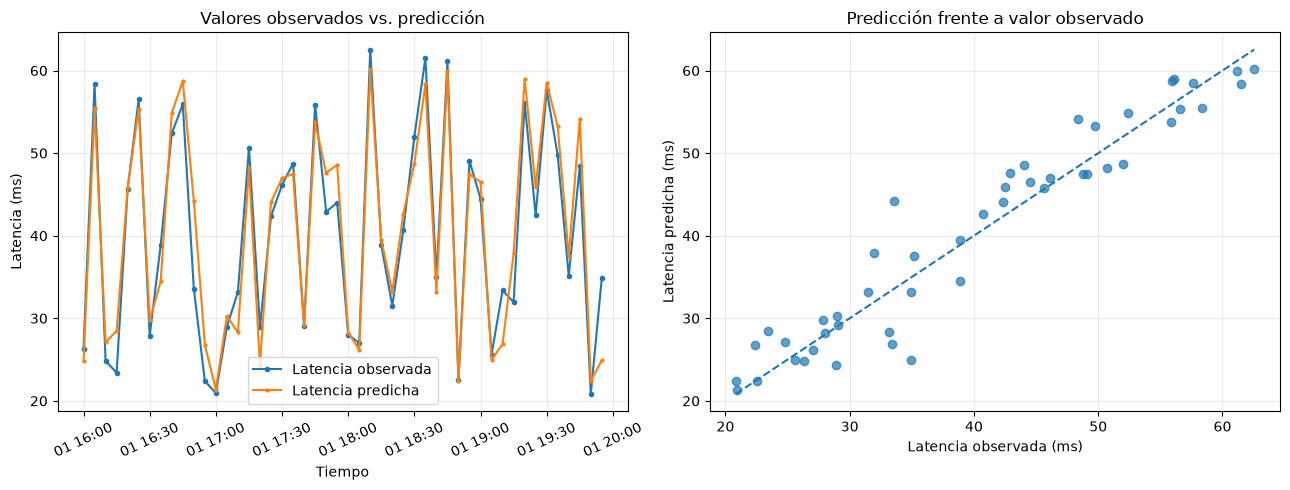

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(test_df["timestamp"], y_test.values, label="Latencia observada", marker="o", markersize=3)
axes[0].plot(test_df["timestamp"], best_prediction, label="Latencia predicha", marker=".", markersize=4)
axes[0].set_title("Valores observados vs. predicción")
axes[0].set_xlabel("Tiempo")
axes[0].set_ylabel("Latencia (ms)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend()

axes[1].scatter(y_test, best_prediction, alpha=0.7)
lims = [
    min(float(y_test.min()), float(np.min(best_prediction))),
    max(float(y_test.max()), float(np.max(best_prediction)))
]
axes[1].plot(lims, lims, linestyle="--")
axes[1].set_title("Predicción frente a valor observado")
axes[1].set_xlabel("Latencia observada (ms)")
axes[1].set_ylabel("Latencia predicha (ms)")

plt.tight_layout()
plt.show()

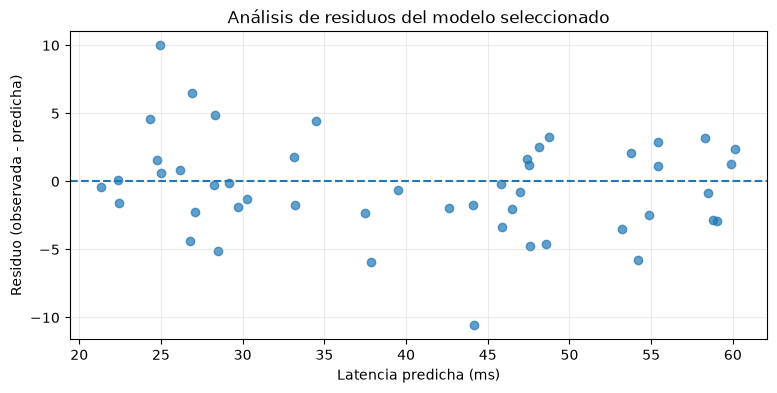

In [13]:
residuals = y_test.to_numpy() - best_prediction
plt.figure(figsize=(9, 4))
plt.scatter(best_prediction, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.title("Análisis de residuos del modelo seleccionado")
plt.xlabel("Latencia predicha (ms)")
plt.ylabel("Residuo (observada - predicha)")
plt.show()

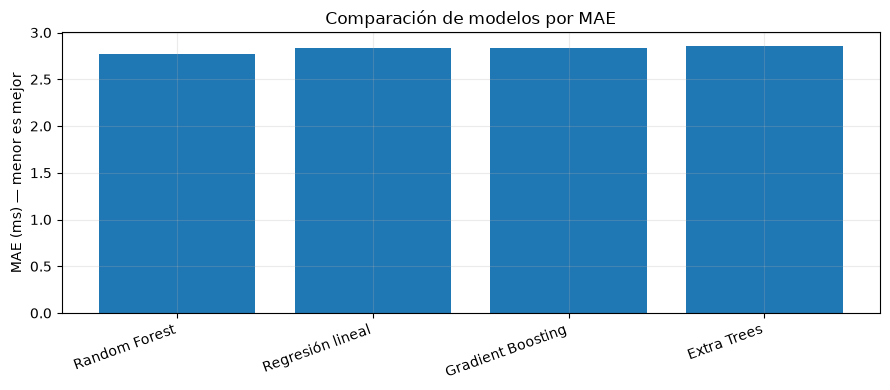

In [14]:
plt.figure(figsize=(9, 4))
plt.bar(model_results["Modelo"], model_results["MAE_ms"])
plt.title("Comparación de modelos por MAE")
plt.ylabel("MAE (ms) — menor es mejor")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 9. Importancia de variables

La importancia por permutación estima cuánto empeora el MAE cuando se desordena una variable. Una caída mayor del desempeño indica que el modelo depende más de esa característica. Se calcula únicamente sobre el bloque de prueba.

,Variable,Importancia_media,Desviacion
0,distance_km,11.2116,1.3415
1,relative_velocity_km_s,0.4303,0.1081
3,time_cos,0.0221,0.0221
2,time_sin,-0.0000,0.0000


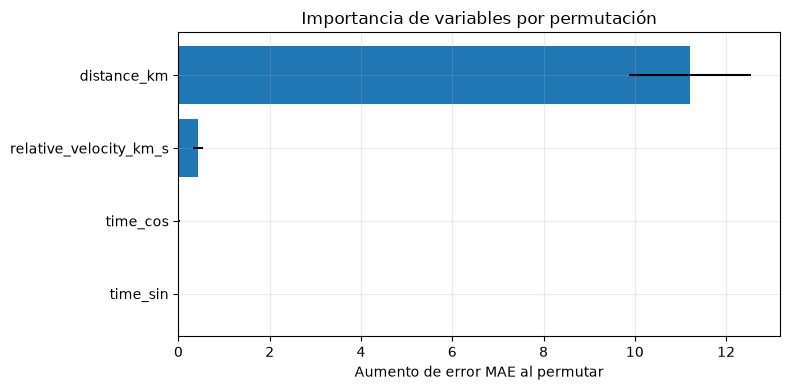

In [15]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=20, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error"
)
importance = pd.DataFrame({
    "Variable": FEATURES,
    "Importancia_media": perm.importances_mean,
    "Desviacion": perm.importances_std
}).sort_values("Importancia_media", ascending=False)

display(importance.round(4))
plt.figure(figsize=(8, 4))
plt.barh(importance["Variable"], importance["Importancia_media"],
         xerr=importance["Desviacion"])
plt.gca().invert_yaxis()
plt.title("Importancia de variables por permutación")
plt.xlabel("Aumento de error MAE al permutar")
plt.tight_layout()
plt.show()

## 10. Construcción del grafo de comunicación

Se toma el primer instante disponible de la base orbital (12 satélites). Cada satélite representa un nodo. Se crea un enlace candidato cuando la distancia euclidiana entre dos posiciones es menor o igual que un umbral geométrico de 9,000 km.

La construcción de todos los pares requiere comparar:

\[
\frac{V(V-1)}{2} \Rightarrow O(V^2)
\]

donde \(V\) es el número de satélites considerados.

**Importante:** el umbral de 9,000 km es una regla didáctica de conectividad. No sustituye un análisis de línea de vista, obstrucción terrestre, antenas, ventanas de enlace ni restricciones físicas completas.

In [16]:
time0 = orbit["time_min"].min()
snapshot = orbit[orbit["time_min"] == time0].copy().set_index("satellite_id")

satellite_ids = list(snapshot.index)
positions = snapshot[["x_km", "y_km", "z_km"]].to_dict("index")
velocities = snapshot[["vx_km_s", "vy_km_s", "vz_km_s"]].to_dict("index")

DISTANCE_THRESHOLD_KM = 9000.0
candidate_edges = []

for i, sat_a in enumerate(satellite_ids):
    for sat_b in satellite_ids[i + 1:]:
        pa = np.array(list(positions[sat_a].values()), dtype=float)
        pb = np.array(list(positions[sat_b].values()), dtype=float)
        va = np.array(list(velocities[sat_a].values()), dtype=float)
        vb = np.array(list(velocities[sat_b].values()), dtype=float)

        distance = float(np.linalg.norm(pa - pb))
        relative_speed = float(np.linalg.norm(va - vb))

        if distance <= DISTANCE_THRESHOLD_KM:
            row_a = snapshot.loc[sat_a]
            row_b = snapshot.loc[sat_b]
            packet_loss_proxy = float(
                (row_a["packet_loss_pct_synthetic"] + row_b["packet_loss_pct_synthetic"]) / 2
            )
            candidate_edges.append({
                "source": sat_a,
                "target": sat_b,
                "distance_km": distance,
                "relative_velocity_km_s": relative_speed,
                "packet_loss_proxy_pct": packet_loss_proxy
            })

edges_df = pd.DataFrame(candidate_edges)
print("Nodos:", len(satellite_ids))
print("Enlaces candidatos:", len(edges_df))
display(edges_df.head())

Nodos: 12
Enlaces candidatos: 24


,source,target,distance_km,relative_velocity_km_s,packet_loss_proxy_pct
0,SAT-01,SAT-02,3582.695723,3.882289,0.426123
1,SAT-01,SAT-03,6921.223409,7.500013,0.630472
2,SAT-01,SAT-11,6921.014809,7.500892,0.619200
3,SAT-01,SAT-12,3582.610893,3.884100,0.746999
4,SAT-02,SAT-03,3582.667444,3.882296,0.516590


## 11. Machine Learning aplicado al costo de los enlaces

Se utiliza el mejor modelo de latencia seleccionado en la sección 7 para estimar latencia en cada enlace candidato. La pérdida de paquetes se aproxima con el promedio de los valores sintéticos de los dos satélites extremos. La disponibilidad se fija en la mediana del conjunto QoS porque la base orbital no contiene una variable de disponibilidad por satélite.

Por tanto, las métricas de cada arista son **estimaciones de escenario** y no mediciones reales de enlaces intersatelitales. Se usa la función de costo documentada en la sección 5 para obtener pesos positivos que Dijkstra y Bellman-Ford pueden minimizar.

In [17]:
availability_proxy = float(qos["availability_pct"].median())
minute_for_graph = float(time0)
minute_sin = np.sin(2 * np.pi * minute_for_graph / 1440)
minute_cos = np.cos(2 * np.pi * minute_for_graph / 1440)

edge_features = pd.DataFrame({
    "distance_km": edges_df["distance_km"],
    "relative_velocity_km_s": edges_df["relative_velocity_km_s"],
    "time_sin": minute_sin,
    "time_cos": minute_cos
})

edges_df["predicted_latency_ms"] = np.maximum(0, best_model.predict(edge_features))
edges_df["availability_proxy_pct"] = availability_proxy
edges_df["predicted_qos_cost"] = (
    edges_df["predicted_latency_ms"]
    + 1.8 * edges_df["packet_loss_proxy_pct"]
    + 0.8 * (100 - edges_df["availability_proxy_pct"])
)

display(edges_df.sort_values("predicted_qos_cost").head(10).round(3))

,source,target,distance_km,relative_velocity_km_s,packet_loss_proxy_pct,predicted_latency_ms,availability_proxy_pct,predicted_qos_cost
0,SAT-01,SAT-02,3582.696,3.882,0.426,48.161,97.857,50.643
4,SAT-02,SAT-03,3582.667,3.882,0.517,48.161,97.857,50.806
3,SAT-01,SAT-12,3582.611,3.884,0.747,48.161,97.857,51.220
21,SAT-10,SAT-11,3582.684,3.882,0.801,48.161,97.857,51.317
19,SAT-09,SAT-10,3582.651,3.882,0.808,48.161,97.857,51.329
23,SAT-11,SAT-12,3582.705,3.882,0.826,48.161,97.857,51.363
13,SAT-06,SAT-07,3582.574,3.882,0.840,48.161,97.857,51.387
7,SAT-03,SAT-04,3582.632,3.882,0.870,48.161,97.857,51.442
17,SAT-08,SAT-09,3582.616,3.882,0.909,48.161,97.857,51.511
15,SAT-07,SAT-08,3582.588,3.882,0.947,48.161,97.857,51.579


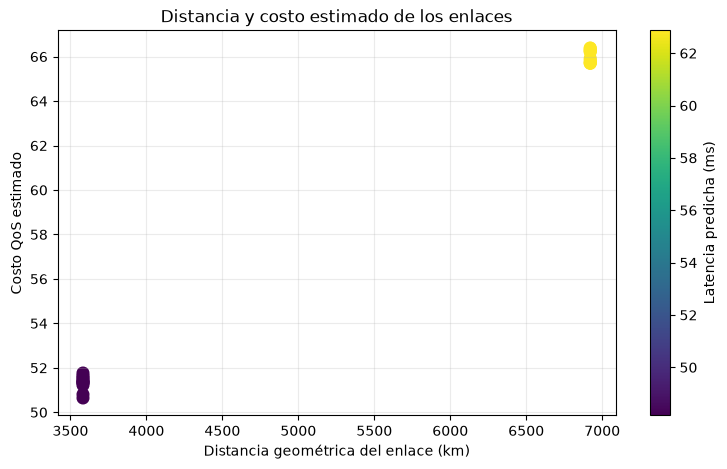

In [18]:
plt.figure(figsize=(9, 5))
plt.scatter(edges_df["distance_km"], edges_df["predicted_qos_cost"],
            c=edges_df["predicted_latency_ms"], s=70)
plt.colorbar(label="Latencia predicha (ms)")
plt.xlabel("Distancia geométrica del enlace (km)")
plt.ylabel("Costo QoS estimado")
plt.title("Distancia y costo estimado de los enlaces")
plt.show()

## 12. Optimización de rutas: Dijkstra y Bellman-Ford

Los dos algoritmos calculan caminos de costo mínimo en el grafo ponderado:

- **Dijkstra:** con cola de prioridad y listas de adyacencia, su complejidad típica es \(O((V+E)\log V)\). Requiere pesos no negativos.
- **Bellman-Ford:** relaja todas las aristas repetidamente; su complejidad es \(O(VE)\). Puede detectar ciclos de peso negativo.

Como los costos QoS se construyeron con métricas no negativas, Dijkstra es apropiado para este escenario. Bellman-Ford se incluye como comparación algorítmica.

In [19]:
G = nx.Graph()
G.add_nodes_from(satellite_ids)

for _, row in edges_df.iterrows():
    G.add_edge(
        row["source"], row["target"],
        weight=float(row["predicted_qos_cost"]),
        distance_km=float(row["distance_km"]),
        predicted_latency_ms=float(row["predicted_latency_ms"]),
        packet_loss_proxy_pct=float(row["packet_loss_proxy_pct"])
    )

print("Grafo conexo:", nx.is_connected(G))
print("Número de componentes:", nx.number_connected_components(G))
print("Nodos:", G.number_of_nodes(), "| Aristas:", G.number_of_edges())

ORIGIN = "SAT-01"
DESTINATION = "SAT-07"

if not nx.has_path(G, ORIGIN, DESTINATION):
    raise ValueError("No existe camino entre el origen y el destino con el umbral actual.")

dijkstra_path = nx.dijkstra_path(G, ORIGIN, DESTINATION, weight="weight")
dijkstra_cost = nx.dijkstra_path_length(G, ORIGIN, DESTINATION, weight="weight")

bellman_path = nx.bellman_ford_path(G, ORIGIN, DESTINATION, weight="weight")
bellman_cost = nx.bellman_ford_path_length(G, ORIGIN, DESTINATION, weight="weight")

print("Ruta Dijkstra:", " -> ".join(dijkstra_path))
print("Costo Dijkstra:", round(dijkstra_cost, 4))
print("Ruta Bellman-Ford:", " -> ".join(bellman_path))
print("Costo Bellman-Ford:", round(bellman_cost, 4))
print("Coinciden los costos óptimos:", np.isclose(dijkstra_cost, bellman_cost))

Grafo conexo: True
Número de componentes: 1
Nodos: 12 | Aristas: 24
Ruta Dijkstra: SAT-01 -> SAT-11 -> SAT-09 -> SAT-07
Costo Dijkstra: 197.4747
Ruta Bellman-Ford: SAT-01 -> SAT-11 -> SAT-09 -> SAT-07
Costo Bellman-Ford: 197.4747
Coinciden los costos óptimos: True


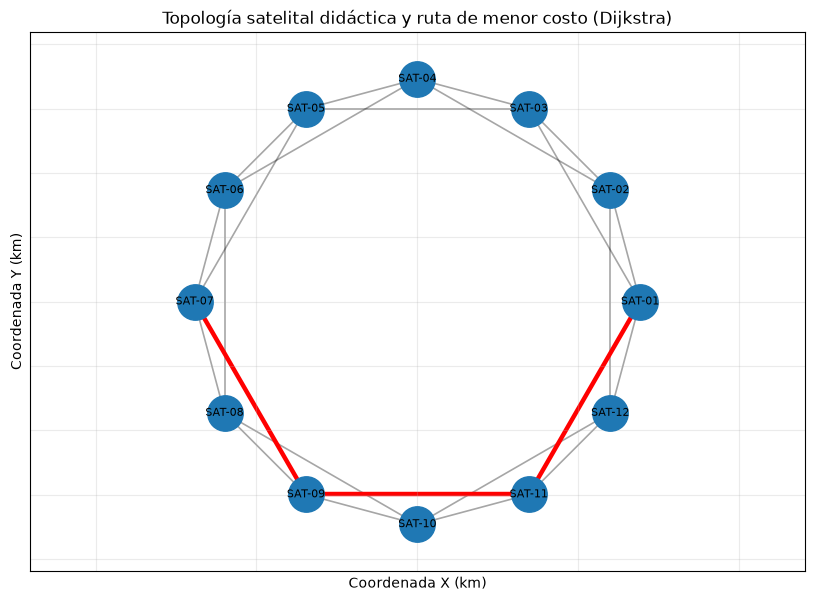

In [20]:
pos_graph = {
    sat: (float(snapshot.loc[sat, "x_km"]), float(snapshot.loc[sat, "y_km"]))
    for sat in satellite_ids
}
plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(G, pos_graph, alpha=0.35, width=1.2)
nx.draw_networkx_nodes(G, pos_graph, node_size=650)
nx.draw_networkx_labels(G, pos_graph, font_size=8)

route_edges = list(zip(dijkstra_path[:-1], dijkstra_path[1:]))
nx.draw_networkx_edges(
    G, pos_graph, edgelist=route_edges,
    width=3.2, edge_color="red"
)
plt.title("Topología satelital didáctica y ruta de menor costo (Dijkstra)")
plt.xlabel("Coordenada X (km)")
plt.ylabel("Coordenada Y (km)")
plt.axis("equal")
plt.show()

In [21]:
route_rows = []
for u, v in route_edges:
    data = G[u][v]
    route_rows.append({
        "Origen": u,
        "Destino": v,
        "Distancia_km": data["distance_km"],
        "Latencia_ML_ms": data["predicted_latency_ms"],
        "Perdida_proxy_pct": data["packet_loss_proxy_pct"],
        "Costo_QoS": data["weight"]
    })
route_table = pd.DataFrame(route_rows)
display(route_table.round(3))

,Origen,Destino,Distancia_km,Latencia_ML_ms,Perdida_proxy_pct,Costo_QoS
0,SAT-01,SAT-11,6921.015,62.866,0.619,65.695
1,SAT-11,SAT-09,6921.194,62.866,0.705,65.850
2,SAT-09,SAT-07,6921.055,62.866,0.750,65.930


## 13. Comparación de costo: ruta por distancia frente a ruta por QoS

Se calcula también una ruta mínima por distancia geométrica. La comparación muestra que el camino más corto físicamente puede no ser el camino con menor costo QoS estimado. La diferencia depende de las predicciones y de los pesos elegidos.

In [22]:
for u, v, data in G.edges(data=True):
    data["distance_weight"] = data["distance_km"]

distance_path = nx.dijkstra_path(G, ORIGIN, DESTINATION, weight="distance_weight")
distance_total_km = nx.dijkstra_path_length(G, ORIGIN, DESTINATION, weight="distance_weight")

comparison = pd.DataFrame({
    "Criterio": ["Menor distancia", "Menor costo QoS estimado"],
    "Ruta": [" -> ".join(distance_path), " -> ".join(dijkstra_path)],
    "Valor": [distance_total_km, dijkstra_cost],
    "Unidad": ["km", "costo QoS"]
})
display(comparison)

,Criterio,Ruta,Valor,Unidad
0,Menor distancia,SAT-01 -> SAT-11 -> SAT-09 -> SAT-07,20763.263795,km
1,Menor costo QoS estimado,SAT-01 -> SAT-11 -> SAT-09 -> SAT-07,197.474653,costo QoS


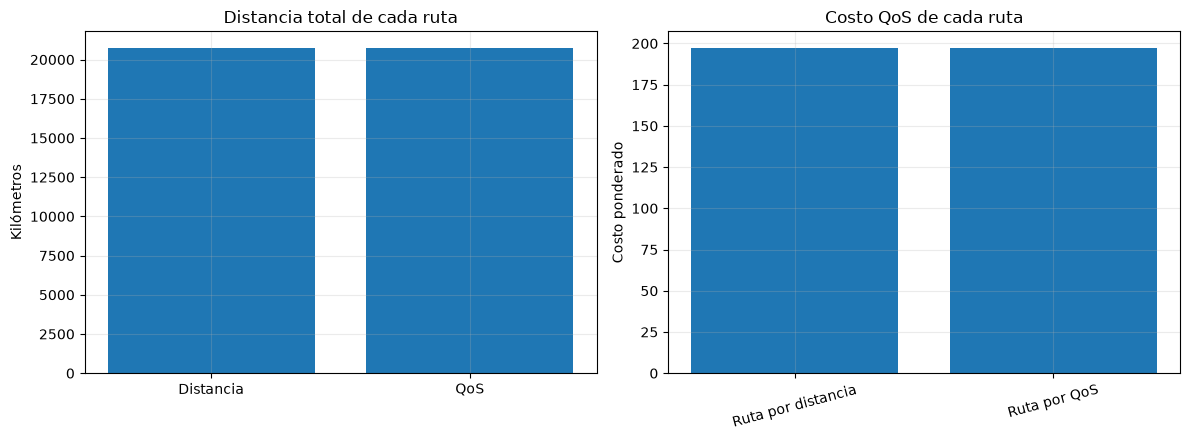

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(["Distancia", "QoS"], [distance_total_km, sum(G[u][v]["distance_km"] for u,v in route_edges)])
axes[0].set_title("Distancia total de cada ruta")
axes[0].set_ylabel("Kilómetros")

axes[1].bar(["Ruta por distancia", "Ruta por QoS"], [
    sum(G[u][v]["weight"] for u,v in zip(distance_path[:-1], distance_path[1:])),
    dijkstra_cost
])
axes[1].set_title("Costo QoS de cada ruta")
axes[1].set_ylabel("Costo ponderado")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 14. Complejidad computacional teórica

Sea \(V\) el número de satélites (vértices) y \(E\) el número de enlaces candidatos (aristas).

| Proceso | Complejidad temporal típica | Explicación |
|---|---:|---|
| Construcción por pares | \(O(V^2)\) | Se revisan todos los pares de satélites. |
| Dijkstra con heap | \(O((V+E)\log V)\) | Extrae repetidamente el nodo con menor distancia provisional. |
| Bellman-Ford | \(O(VE)\) | Relaja las aristas hasta \(V-1\) iteraciones. |
| Memoria del grafo | \(O(V+E)\) | Listas de adyacencia y pesos. |
| Predicción con ensamble de árboles | Depende del número de árboles y su profundidad | Cada observación recorre los árboles del modelo. |

La complejidad del entrenamiento de Random Forest o Extra Trees depende del número de muestras \(n\), variables \(p\), árboles \(T\) y profundidad. Como aproximación práctica para árboles balanceados, el entrenamiento suele crecer aproximadamente como \(O(T n \log n)\), mientras que predecir una observación cuesta aproximadamente \(O(T \log n)\). No es una cota universal para cualquier conjunto ni configuración.

**Diferencia importante:** el tiempo medido en una computadora es evidencia empírica del experimento; la notación Big-O describe cómo escala el algoritmo cuando crece el tamaño de la entrada.

## 15. Medición experimental de tiempos de ejecución

Se generan grafos de prueba de distintos tamaños y se mide el tiempo de Dijkstra y Bellman-Ford. Se usa una semilla fija para reproducibilidad. Los tiempos dependen del hardware, versión de Python, densidad del grafo y librería; no deben confundirse con las cotas teóricas.

In [24]:
def make_connected_random_graph(n, seed):
    rng = np.random.default_rng(seed)
    graph = nx.path_graph(n)  # árbol generador conectado y compatible con NetworkX 3.x
    # Agregar aristas extra con probabilidad controlada.
    for i in range(n):
        for j in range(i + 1, n):
            if not graph.has_edge(i, j) and rng.random() < 0.035:
                graph.add_edge(i, j)
    for u, v in graph.edges():
        graph[u][v]["weight"] = float(rng.uniform(0.1, 10.0))
    return graph

sizes = [20, 40, 60, 80, 100]
benchmark_rows = []

for n_nodes in sizes:
    graph = make_connected_random_graph(n_nodes, RANDOM_STATE + n_nodes)
    source, target = 0, n_nodes - 1

    t0 = time.perf_counter()
    nx.dijkstra_path_length(graph, source, target, weight="weight")
    dijkstra_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    nx.bellman_ford_path_length(graph, source, target, weight="weight")
    bellman_seconds = time.perf_counter() - t0

    benchmark_rows.append({
        "Nodos_V": n_nodes,
        "Aristas_E": graph.number_of_edges(),
        "Dijkstra_s": dijkstra_seconds,
        "Bellman_Ford_s": bellman_seconds
    })

benchmark = pd.DataFrame(benchmark_rows)
display(benchmark.round(6))

,Nodos_V,Aristas_E,Dijkstra_s,Bellman_Ford_s
0,20,23,0.000022,0.000028
1,40,57,0.000030,0.000048
2,60,121,0.000035,0.000079
3,80,174,0.000076,0.000126
4,100,267,0.000084,0.000172


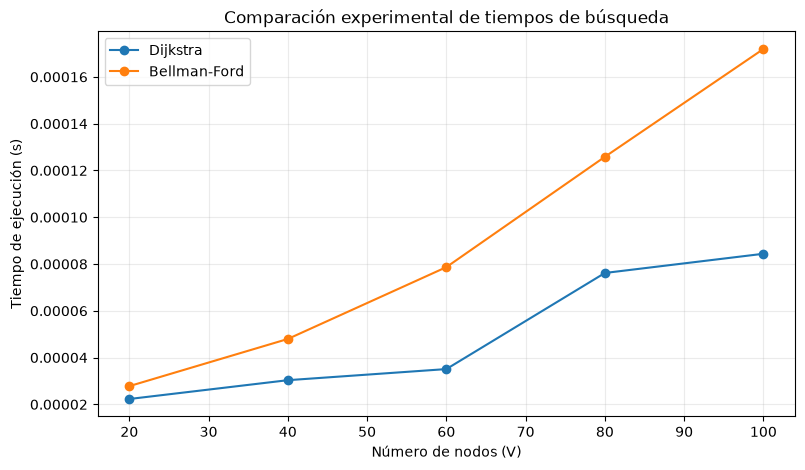

In [25]:
plt.figure(figsize=(9, 5))
plt.plot(benchmark["Nodos_V"], benchmark["Dijkstra_s"], marker="o", label="Dijkstra")
plt.plot(benchmark["Nodos_V"], benchmark["Bellman_Ford_s"], marker="o", label="Bellman-Ford")
plt.xlabel("Número de nodos (V)")
plt.ylabel("Tiempo de ejecución (s)")
plt.title("Comparación experimental de tiempos de búsqueda")
plt.legend()
plt.show()

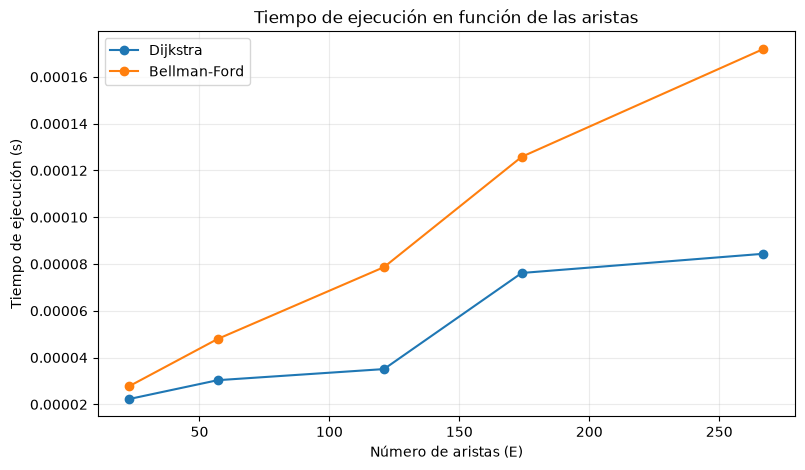

In [26]:
plt.figure(figsize=(9, 5))
plt.plot(benchmark["Aristas_E"], benchmark["Dijkstra_s"], marker="o", label="Dijkstra")
plt.plot(benchmark["Aristas_E"], benchmark["Bellman_Ford_s"], marker="o", label="Bellman-Ford")
plt.xlabel("Número de aristas (E)")
plt.ylabel("Tiempo de ejecución (s)")
plt.title("Tiempo de ejecución en función de las aristas")
plt.legend()
plt.show()

## 16. Complejidad del entrenamiento y predicción de Machine Learning

Se mide el tiempo de entrenamiento y predicción de Random Forest al incrementar el número de observaciones. Esta prueba complementa el análisis Big-O con mediciones de la implementación concreta.

In [27]:
ml_sizes = sorted(set([max(30, int(len(X_train)*f)) for f in [0.25, 0.50, 0.75, 1.0]]))
ml_bench_rows = []
for n_samples in ml_sizes:
    X_part = X_train.iloc[:n_samples]
    y_part = y_train.iloc[:n_samples]
    model = RandomForestRegressor(
        n_estimators=120, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1
    )
    t0 = time.perf_counter()
    model.fit(X_part, y_part)
    fit_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    model.predict(X_test)
    pred_time = time.perf_counter() - t0

    ml_bench_rows.append({
        "Muestras_entrenamiento": n_samples,
        "Tiempo_entrenamiento_s": fit_time,
        "Tiempo_prediccion_bloque_s": pred_time
    })

ml_benchmark = pd.DataFrame(ml_bench_rows)
display(ml_benchmark.round(6))

,Muestras_entrenamiento,Tiempo_entrenamiento_s,Tiempo_prediccion_bloque_s
0,48,0.053744,0.012816
1,96,0.061525,0.013068
2,144,0.062856,0.014629
3,192,0.063799,0.011580


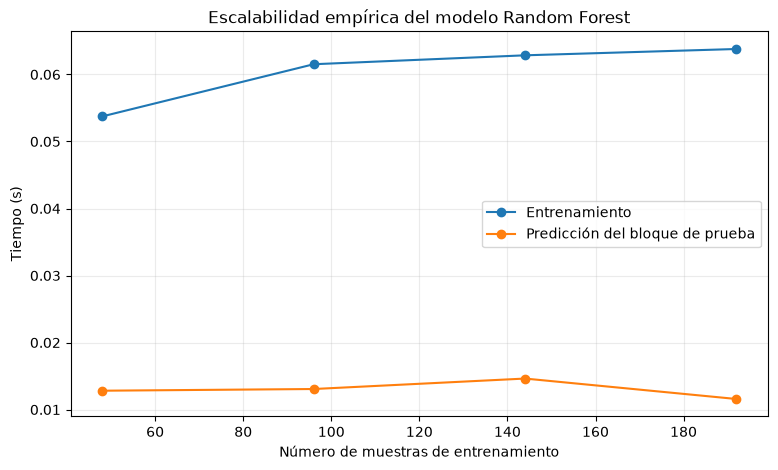

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ml_benchmark["Muestras_entrenamiento"], ml_benchmark["Tiempo_entrenamiento_s"],
        marker="o", label="Entrenamiento")
ax.plot(ml_benchmark["Muestras_entrenamiento"], ml_benchmark["Tiempo_prediccion_bloque_s"],
        marker="o", label="Predicción del bloque de prueba")
ax.set_xlabel("Número de muestras de entrenamiento")
ax.set_ylabel("Tiempo (s)")
ax.set_title("Escalabilidad empírica del modelo Random Forest")
ax.legend()
plt.show()

## 17. Resultados y discusión

El análisis debe interpretarse en dos niveles:

1. **Machine Learning:** el mejor modelo es el que obtiene menor MAE en el bloque temporal reservado. El R² indica qué proporción de variabilidad explica en ese bloque. Si el desempeño es bajo, no debe ocultarse: puede indicar que las variables disponibles no explican suficientemente la latencia.
2. **Complejidad computacional:** Dijkstra y Bellman-Ford deben producir el mismo costo óptimo en este grafo con pesos no negativos. Dijkstra suele ser más eficiente para este escenario; Bellman-Ford tiene la ventaja de admitir pesos negativos y detectar ciclos negativos, aunque su costo temporal es mayor.

La selección de una ruta por QoS integra la predicción de latencia con pérdida y disponibilidad. De esta manera, el Machine Learning no queda como un apartado aislado: su salida alimenta directamente el peso de los enlaces que utiliza el algoritmo de optimización.

In [29]:
print("MODELO SELECCIONADO:", best_name)
print("MAE:", round(float(model_results.loc[0, "MAE_ms"]), 4), "ms")
print("RMSE:", round(float(model_results.loc[0, "RMSE_ms"]), 4), "ms")
print("R2:", round(float(model_results.loc[0, "R2"]), 4))
print()
print("RUTA DE MENOR COSTO QoS:", " -> ".join(dijkstra_path))
print("COSTO TOTAL QoS:", round(float(dijkstra_cost), 4))
print("RUTA DE MENOR DISTANCIA:", " -> ".join(distance_path))
print("DISTANCIA TOTAL:", round(float(distance_total_km), 3), "km")
print()
print("Dijkstra y Bellman-Ford coinciden:",
      bool(np.isclose(dijkstra_cost, bellman_cost)))

MODELO SELECCIONADO: Random Forest
MAE: 2.7723 ms
RMSE: 3.5808 ms
R2: 0.9166

RUTA DE MENOR COSTO QoS: SAT-01 -> SAT-11 -> SAT-09 -> SAT-07
COSTO TOTAL QoS: 197.4747
RUTA DE MENOR DISTANCIA: SAT-01 -> SAT-11 -> SAT-09 -> SAT-07
DISTANCIA TOTAL: 20763.264 km

Dijkstra y Bellman-Ford coinciden: True


## 18. Conclusiones

El estudio integra Machine Learning y complejidad computacional en un mismo flujo. Los modelos predictivos estiman la latencia de los enlaces a partir de sus características geométricas y temporales. Las estimaciones se incorporan a una función de costo QoS, que permite ponderar las aristas de un grafo y buscar una ruta de menor costo.

La comparación entre Dijkstra y Bellman-Ford permite relacionar la calidad de la solución con el costo computacional de obtenerla. La construcción del grafo mediante comparación de pares presenta crecimiento cuadrático \(O(V^2)\); Dijkstra con heap tiene una complejidad típica \(O((V+E)\log V)\), mientras que Bellman-Ford requiere \(O(VE)\).

**Conclusión principal:** Machine Learning aporta información predictiva para estimar el costo de los enlaces; los algoritmos de caminos utilizan esa información para optimizar la ruta. La complejidad computacional permite determinar qué método ofrece una solución eficiente conforme aumenta el tamaño de la red.

### Limitaciones y trabajo futuro
- Los datos incluidos son sintéticos y didácticos.
- La disponibilidad usada para cada enlace del grafo es una mediana global de la base QoS, porque la base orbital no incluye disponibilidad individual por satélite.
- La topología se construye con distancia euclidiana y un umbral fijo; una versión física debe incorporar línea de vista, obstrucción terrestre y ventanas de comunicación.
- Para una evaluación experimental real se necesitan registros QoS etiquetados por enlace y tiempo, así como elementos orbitales y una propagación validada.
- Como trabajo futuro se recomienda incorporar validación temporal con más periodos, calibración de la función de costo y evaluación con redes de mayor tamaño.

### Referencias técnicas
- scikit-learn. (s. f.). *Ensemble methods*. https://scikit-learn.org/stable/modules/ensemble.html
- scikit-learn. (s. f.). *Model evaluation: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html
- NetworkX. (s. f.). *Shortest paths*. https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html
- Cormen, T. H., Leiserson, C. E., Rivest, R. L., & Stein, C. (2022). *Introduction to algorithms* (4th ed.). MIT Press.